# 33. Feature diagnostics for the current three-model protocol

**Purpose:** understand which input groups provide additional predictive information. This notebook does not select a new final model and does not remove pressure from the main model.

Same 585 ZIPs, 243 daily forecast dates (April 30–December 28, 2020), future days 1/2/3, rolling 60-day training windows and weekly refits. No 2021–2023 evaluation. Counts use recorded illness-onset dates; historical reporting availability is unverified.

**Main feature pool:** 15 local-history + 2 pressure + 17 calendar inputs. ZIP identity is retained in every variant.

**Four outputs:** (1) retrained group-ablation comparisons, (2) exploratory predictive-loss p-values and 95% intervals, (3) tree training-importance rankings, (4) descriptive DP coefficient stability. A high importance is not a causal effect or a p-value.

## Saved findings from this run

Removing local history raises MAE by 23.55% (DP), 3.46% (XGBoost) and 88.20% (RF). Primary HAC7/Holm tests show differences, but DP/RF lose the 0.05 cutoff under the 28-lag sensitivity setting. Pressure/calendar have small, mixed changes and intervals crossing zero. Main full-feature models remain unchanged. Tree training usage is dominated by the 7/14-day case means. Read `READ_FIRST_CN.md` for plain-language interpretation.

Counts, direction and shape can move differently. Supplementary direction improvements can reflect more flat predictions, rather than better outbreak warning.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/"rolling_trajectory_outputs").exists() and (ROOT/"Weikun").is_dir():
    ROOT=ROOT/"Weikun"
OUTPUT=ROOT/"feature_diagnostics_outputs"/"validation2020_20261102"
OUTPUT.mkdir(parents=True,exist_ok=True)
SOURCE=ROOT/"rolling_trajectory_outputs"/"inputs"/"nj_daily_features.csv.gz"
if not SOURCE.exists(): SOURCE=ROOT/"nj_daily_feature_outputs"/"nj_daily_features.csv.gz"
COHORT=ROOT/"fixed60_trajectory_outputs"/"fixed60_20261027"/"common_regions.csv"
BASELINES={"Dynamic Panel FE":ROOT/"rolling_trajectory_outputs"/"rolling60_weekly_development_20261027"/"predictions.npz", "XGBoost":ROOT/"xgboost_trajectory_outputs"/"xgb60_weekly_development_20261027"/"predictions.npz", "Random Forest":ROOT/"random_forest_trajectory_outputs"/"rf60_weekly_development_20261027"/"predictions.npz"}
print("Results folder:",OUTPUT.resolve())

Results folder: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\feature_diagnostics_outputs\validation2020_20261102


## 1. Load the analysis code
Requires numpy, pandas, scipy, scikit-learn, xgboost, statsmodels and matplotlib. Full reruns retrain 945 models: 3 feature removals × 3 model types × 35 weekly fits × 3 horizons. Hyperparameters and ZIP identity are unchanged. Existing prediction archives are alignment-checked. Large prediction archives stay local; summary tables and figures are suitable for GitHub.

In [2]:
from pathlib import Path
import json,hashlib,time,os
import numpy as np,pandas as pd
GROUPS={
 'core_history':['cases_today','cases_lag_1','cases_lag_7','cases_lag_14'],
 'rolling_level':['cases_mean_7d','cases_mean_14d'],'volatility':['case_std_7d','case_std_14d'],
 'dynamics':['case_acceleration','case_jerk'],
 'local_rates':['case_rate_today_per_100k','case_rate_7d_per_100k','case_rate_14d_per_100k'],
 'sparse_history':['days_since_last_observed_case_censored','no_previous_observed_case'],
 'pressure':['nj_covid_pressure_7d','nj_covid_pressure_14d'],
 'month':[f'target_month_{k}' for k in range(2,13)],'weekday':[f'target_weekday_{k}' for k in range(2,8)]}
FEATURES=sum(GROUPS.values(),[])
FAMILIES={'local_case_history':sum([v for k,v in GROUPS.items() if k not in ['pressure','month','weekday']],[]),
 'commuting_pressure':GROUPS['pressure'],'calendar':GROUPS['month']+GROUPS['weekday']}
MODELS=['Dynamic Panel FE','XGBoost','Random Forest']

def run(source,cohort,baseline_paths,output):
 from scipy import sparse
 from sklearn.ensemble import RandomForestRegressor
 from xgboost import XGBRegressor
 output=Path(output);output.mkdir(parents=True,exist_ok=True)
 ids=pd.read_csv(cohort,dtype={'zip':str})['zip'].to_numpy(dtype='U5')
 dates=pd.date_range('2020-03-01','2020-12-31');origins=np.flatnonzero((dates>='2020-04-30')&(dates<='2020-12-28'))
 numeric=sum([v for k,v in GROUPS.items() if k not in ['month','weekday','sparse_history']],[])
 f=pd.read_csv(source,usecols=['zip','date','pressure_definition']+numeric,dtype={'zip':str},parse_dates=['date'])
 f=f.loc[f.zip.isin(ids)&f.date.isin(dates)]
 assert f.pressure_definition.eq('valid_population_nj_origins_renormalized_v2').all()
 assert not f.duplicated(['zip','date']).any() and len(ids)==585
 arrays={c:f.pivot(index='zip',columns='date',values=c).reindex(index=ids,columns=dates).to_numpy(float) for c in numeric}
 counts=arrays['cases_today'];actual=np.stack([counts[:,origins+h] for h in (1,2,3)],axis=2)
 baselines={}
 for name,path in baseline_paths.items():
  with np.load(path,allow_pickle=False) as z:
   assert np.array_equal(z['zip'],ids) and np.array_equal(z['forecast_origins'],dates[origins].to_numpy())
   assert np.array_equal(z['actual_cases'],actual)
   baselines[name]=np.maximum(z['raw_predictions'].copy(),0)
 variants={g:[i for i,x in enumerate(FEATURES) if x not in xs] for g,xs in FAMILIES.items()}
 predictions={(m,g):np.full_like(actual,np.nan) for m in MODELS for g in variants}
 completed=set()
 for g in variants:
  for m in MODELS:
   path=output/f'predictions_{m.split()[0]}_DROP_{g}.npz'
   if path.exists():
    with np.load(path,allow_pickle=False) as z:
     assert np.array_equal(z['actual_cases'],actual)
     predictions[m,g]=z['predictions'].copy();completed.add((m,g))
 first=dates.get_loc('2020-04-29');fits=np.unique(first+7*((origins-first)//7));logs=[]
 for fit in fits:
  lo=fit-59;batch=np.flatnonzero((origins>=fit)&(origins<fit+7));last=np.full(len(ids),-1)
  gap=np.full_like(counts,np.nan);never=np.full_like(counts,np.nan)
  for t in range(lo,int(origins[batch[-1]])+1):
   last=np.where(counts[:,t]>0,t,last);never[:,t]=last<0;gap[:,t]=np.where(last>=0,t-last,t-lo+1)
  arrays['days_since_last_observed_case_censored']=gap;arrays['no_previous_observed_case']=never
  for hh,h in enumerate((1,2,3)):
   train=np.arange(lo+14,fit-h+1);target=dates+pd.Timedelta(days=h)
   for k in range(2,13):arrays[f'target_month_{k}']=np.broadcast_to((target.month==k).astype(float),counts.shape)
   for k in range(2,8):arrays[f'target_weekday_{k}']=np.broadcast_to((target.dayofweek==k-1).astype(float),counts.shape)
   xt=np.stack([arrays[x][:,train] for x in FEATURES],axis=2);xp=np.stack([arrays[x][:,origins[batch]] for x in FEATURES],axis=2);yt=counts[:,train+h]
   assert np.isfinite(xt).all() and np.isfinite(xp).all()
   assert train[-1]+h<=fit and np.all(origins[batch]+h>fit) and lo>=0
   for g,cols in variants.items():
    xx,pp=xt[:,:,cols],xp[:,:,cols];features=[FEATURES[i] for i in cols]
    for m in MODELS:
     if (m,g) in completed:continue
     start=time.time()
     if m=='Dynamic Panel FE':
      xm=xx.mean(axis=1);ym=yt.mean(axis=1);xc=xx-xm[:,None];yc=yt-ym[:,None]
      norms=np.sqrt((xc*xc).mean(axis=(0,1)));scale=np.where(norms>1e-10,norms,1);z=(xc/scale).reshape(-1,len(cols));keep=[];q=[]
      for j in range(len(cols)):
       if norms[j]<1e-10:continue
       v=z[:,j].copy()
       for _ in range(2):
        for u in q:v-=u*(u@v)
       length=np.linalg.norm(v)
       if length<=1e-7*np.sqrt(len(v)):continue
       keep.append(j);q.append(v/length)
      b=np.linalg.lstsq(z[:,keep],yc.ravel(),rcond=None)[0]/scale[keep]
      yhat=np.einsum('ntp,p->nt',pp[:,:,keep],b)+(ym-xm[:,keep]@b)[:,None]
     elif m=='XGBoost':
      def design(v):
       d=pd.DataFrame(v.reshape(-1,len(cols)),columns=features);d['region_id']=pd.Categorical(np.repeat(ids,v.shape[1]),categories=ids);return d
      model=XGBRegressor(objective='reg:squarederror',tree_method='hist',n_estimators=200,max_depth=3,learning_rate=.05,min_child_weight=20,subsample=.8,colsample_bytree=1.,reg_lambda=5.,reg_alpha=0.,max_bin=128,enable_categorical=True,max_cat_to_onehot=4,max_cat_threshold=64,random_state=20261027,n_jobs=4)
      model.fit(design(xx),yt.ravel());yhat=model.predict(design(pp)).reshape(len(ids),len(batch))
     else:
      def design(v,fmt):
       rows=len(ids)*v.shape[1];identity=sparse.csr_matrix((np.ones(rows,dtype=np.float32),(np.arange(rows),np.repeat(np.arange(len(ids)),v.shape[1]))),shape=(rows,len(ids)))
       return sparse.hstack([sparse.csr_matrix(v.reshape(rows,len(cols)).astype(np.float32)),identity],format=fmt)
      model=RandomForestRegressor(n_estimators=200,max_depth=8,min_samples_leaf=20,max_features=1.,bootstrap=True,max_samples=.8,criterion='squared_error',random_state=20261027,n_jobs=4)
      model.fit(design(xx,'csc'),yt.ravel());yhat=model.predict(design(pp,'csr')).reshape(len(ids),len(batch))
     predictions[m,g][:,batch,hh]=np.maximum(yhat,0)
     logs.append(dict(model=m,drop_group=g,fit_date=str(dates[fit].date()),window_start=str(dates[lo].date()),latest_training_target=str(dates[train[-1]+h].date()),first_forecast_target=str(dates[origins[batch[0]]+h].date()),horizon=h,features=len(cols),seconds=time.time()-start))
  print('Completed diagnostic refit',dates[fit].date(),flush=True)
 for (m,g),pred in predictions.items():
  assert np.isfinite(pred).all()
  if (m,g) not in completed:np.savez_compressed(output/f'predictions_{m.split()[0]}_DROP_{g}.npz',predictions=pred,actual_cases=actual,zip=ids,daily_forecast_dates=dates[origins].to_numpy(),horizons=[1,2,3])
 if logs:pd.DataFrame(logs).to_csv(output/'training_audit.csv',index=False)
 summarize(actual,baselines,predictions,dates[origins],output)
 protocol=dict(scope='Exploratory 2020 validation diagnostics, not untouched testing or causal inference',daily_forecast_dates=['2020-04-30','2020-12-28'],zip_count=585,forecast_dates=243,window_days=60,retrain_every=7,features=FEATURES,families=FAMILIES,identity='Retained in every variant; FE/native category/one-hot by model',primary='Trajectory MAE over the same ZIP-date-horizon observations',delta='DROP MAE minus FULL MAE: positive means keeping the group helps',tests='9 two-sided intercept-only HAC tests of paired daily mean absolute-loss differences; Holm across all 9 primary tests; lags 7 primary and 28 sensitivity',intervals='Paired circular moving-date-block bootstrap, 14-day blocks, 4000 draws, pointwise percentile 95% CI. Entire ZIP cross-section and all horizons travel together.',dependence='Cross-ZIP dependence retained by daily aggregation. Temporal nonstationarity and few waves limit inference.',retrospective='Recorded onset dates; historical reporting availability unverified',pressure='Main full-feature models unchanged. DROP is a diagnostic only.',source_sha256=hashlib.sha256(Path(source).read_bytes()).hexdigest())
 (output/'protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')
 return pd.read_csv(output/'group_ablation_summary.csv')

def summarize(actual,full,preds,dates,output):
 import statsmodels.api as sm
 from statsmodels.stats.multitest import multipletests
 rng=np.random.default_rng(20261102);n=len(dates);B=4000;block=14
 starts=rng.integers(0,n,size=(B,int(np.ceil(n/block))));idx=((starts[:,:,None]+np.arange(block))%n).reshape(B,-1)[:,:n]
 rows=[];daily=[];hrows=[];months=[]
 for (m,g),p in preds.items():
  ef=full[m]-actual;ed=p-actual;d=np.abs(ed).mean(axis=(0,2))-np.abs(ef).mean(axis=(0,2));delta=d.mean();boot=d[idx].mean(axis=1)
  tests=[]
  for lag in [7,28]:
   fit=sm.OLS(d,np.ones((n,1))).fit(cov_type='HAC',cov_kwds={'maxlags':lag,'use_correction':True});tests.append(float(fit.pvalues[0]))
  fm=np.abs(ef).mean();dm=np.abs(ed).mean()
  rows.append(dict(model=m,drop_group=g,FULL_MAE=fm,DROP_MAE=dm,delta_MAE_DROP_minus_FULL=delta,relative_increase_pct=100*delta/fm,ci95_low=np.quantile(boot,.025),ci95_high=np.quantile(boot,.975),p_HAC7_raw=tests[0],p_HAC28_raw=tests[1],FULL_RMSE=np.sqrt((ef**2).mean()),DROP_RMSE=np.sqrt((ed**2).mean()),regions=actual.shape[0],forecast_dates=n,paths=actual.shape[0]*n))
  for t,v in zip(dates,d):daily.append(dict(model=m,drop_group=g,daily_forecast_date=t,delta_MAE_DROP_minus_FULL=v))
  for h in range(3):hrows.append(dict(model=m,drop_group=g,horizon=h+1,FULL_MAE=np.abs(ef[:,:,h]).mean(),DROP_MAE=np.abs(ed[:,:,h]).mean(),delta_MAE_DROP_minus_FULL=(np.abs(ed[:,:,h])-np.abs(ef[:,:,h])).mean()))
  for mon in np.unique(dates.to_period('M')):
   mask=dates.to_period('M')==mon;months.append(dict(model=m,drop_group=g,month=str(mon),delta_MAE_DROP_minus_FULL=d[mask].mean(),dates=int(mask.sum())))
 r=pd.DataFrame(rows);r['p_Holm']=multipletests(r.p_HAC7_raw,method='holm')[1];r['p_HAC28_Holm_sensitivity']=multipletests(r.p_HAC28_raw,method='holm')[1]
 r.to_csv(output/'group_ablation_summary.csv',index=False);pd.DataFrame(daily).to_csv(output/'paired_daily_loss_differences.csv',index=False);pd.DataFrame(hrows).to_csv(output/'group_ablation_by_horizon.csv',index=False);pd.DataFrame(months).to_csv(output/'group_ablation_by_month.csv',index=False)


# Supplementary trajectory diagnostics; no extra significance tests.
display(pd.read_csv(OUTPUT/"group_ablation_trajectory_diagnostics.csv"))


,model,drop_group,variant,direction_agreement,decline_recall,flat_recall,rise_recall,balanced_direction_accuracy,shape_agreement,change_MAE,acceleration_MAE
0,Dynamic Panel FE,local_case_history,FULL,0.281552,0.474345,0.091843,0.585552,0.383913,0.126116,0.896647,1.589743
1,Dynamic Panel FE,local_case_history,DROP,0.369421,0.484554,0.255173,0.553442,0.431056,0.217840,0.877350,1.558658
2,Dynamic Panel FE,commuting_pressure,FULL,0.281552,0.474345,0.091843,0.585552,0.383913,0.126116,0.896647,1.589743
3,Dynamic Panel FE,commuting_pressure,DROP,0.269607,0.537021,0.067832,0.532399,0.379084,0.117210,0.899458,1.597532
4,Dynamic Panel FE,calendar,FULL,0.281552,0.474345,0.091843,0.585552,0.383913,0.126116,0.896647,1.589743
5,Dynamic Panel FE,calendar,DROP,0.274151,0.369280,0.102807,0.625425,0.365838,0.121916,0.870573,1.539748
6,XGBoost,local_case_history,FULL,0.227357,0.475964,0.003779,0.564862,0.348201,0.089951,0.870869,1.548966
7,XGBoost,local_case_history,DROP,0.263058,0.504807,0.065627,0.539520,0.369985,0.125623,0.872585,1.552664
8,XGBoost,commuting_pressure,FULL,0.227357,0.475964,0.003779,0.564862,0.348201,0.089951,0.870869,1.548966
9,XGBoost,commuting_pressure,DROP,0.227146,0.486470,0.002230,0.557708,0.348803,0.089163,0.870259,1.547546


In [3]:
RUN_REFITS=False  # Saved results are already available. Set True only to rerun.
if RUN_REFITS:
    scores=run(SOURCE,COHORT,BASELINES,OUTPUT)
    display(scores)
    import runpy
    runpy.run_path(str(ROOT/"feature_diagnostics_outputs"/"analyze_features.py"),run_name="__main__")
else:
    print("Reading the saved diagnostics; no new model fitting.")

Reading the saved diagnostics; no new model fitting.


## 2. Main group-removal evidence
**Delta = MAE after removal − full-model MAE. Positive means keeping the group helps.** CI = pointwise 14-day circular date-block bootstrap (4,000 draws). P-values = two-sided paired daily-loss HAC test, 7 lags, with Holm correction across nine planned contrasts. The 28-lag version is a sensitivity check. Dates are the inference units; whole ZIP cross-sections and all horizons stay together.

No coefficient significance or causal claim follows from these tests. A group can share information with other groups. Dropping local history still retains pressure based on other ZIPs’ histories. The previously inspected 2020 validation period makes this exploratory evidence.

,model,drop_group,FULL_MAE,DROP_MAE,delta_MAE_DROP_minus_FULL,relative_increase_pct,ci95_low,ci95_high,p_Holm,p_HAC28_Holm_sensitivity
0,Dynamic Panel FE,local_case_history,0.774283,0.956653,0.182370,23.553383,0.092043,0.288168,4.971981e-05,0.057218
1,Dynamic Panel FE,commuting_pressure,0.774283,0.767056,-0.007227,-0.933342,-0.027461,0.010094,1.000000e+00,1.000000
2,Dynamic Panel FE,calendar,0.774283,0.778660,0.004377,0.565338,-0.004488,0.015547,1.000000e+00,1.000000
3,XGBoost,local_case_history,0.754299,0.780394,0.026095,3.459554,0.015151,0.036881,7.137201e-08,0.003731
4,XGBoost,commuting_pressure,0.754299,0.756246,0.001947,0.258157,-0.000759,0.004819,7.297067e-01,0.871619
5,XGBoost,calendar,0.754299,0.756705,0.002405,0.318900,-0.002897,0.008597,1.000000e+00,1.000000
6,Random Forest,local_case_history,0.751885,1.415063,0.663178,88.202006,0.277334,1.120811,6.030210e-04,0.168191
7,Random Forest,commuting_pressure,0.751885,0.749545,-0.002340,-0.311237,-0.006722,0.001597,9.484925e-01,1.000000
8,Random Forest,calendar,0.751885,0.748764,-0.003122,-0.415206,-0.007348,0.000154,7.282867e-01,0.335002


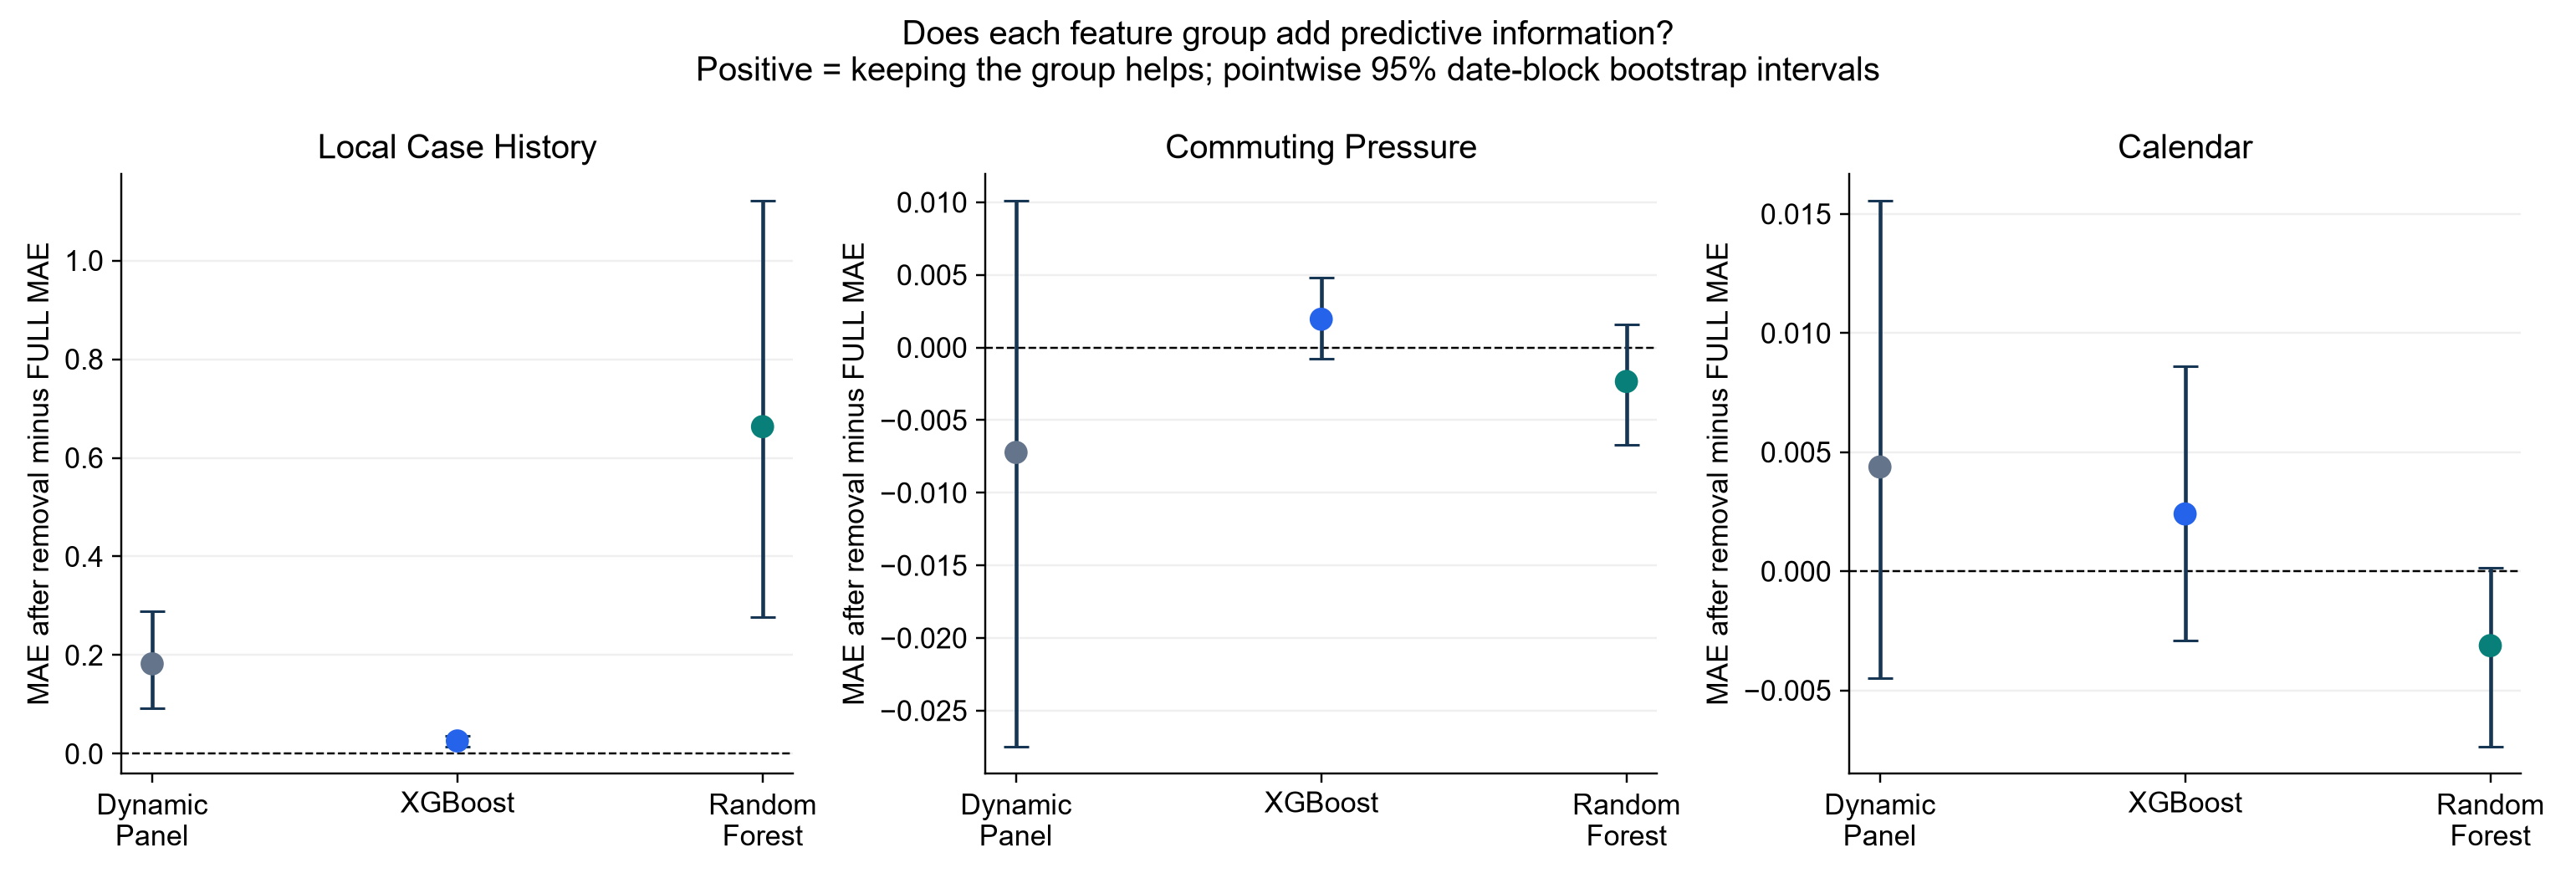

In [4]:
summary=pd.read_csv(OUTPUT/"group_ablation_summary.csv")
display(summary[["model","drop_group","FULL_MAE","DROP_MAE","delta_MAE_DROP_minus_FULL","relative_increase_pct","ci95_low","ci95_high","p_Holm","p_HAC28_Holm_sensitivity"]])
display(Image(filename=str(OUTPUT/"figures"/"03_group_ablation_intervals.png")))

## 3. Does contribution change with horizon or month?
These are descriptive breakdowns, not additional significance tests. April contains one daily forecast date and should not be interpreted as a stable monthly estimate.

,model,drop_group,horizon,FULL_MAE,DROP_MAE,delta_MAE_DROP_minus_FULL
0,Dynamic Panel FE,local_case_history,1,0.746501,0.940669,0.194168
1,Dynamic Panel FE,local_case_history,2,0.772796,0.956318,0.183522
2,Dynamic Panel FE,local_case_history,3,0.803551,0.972971,0.169420
3,Dynamic Panel FE,commuting_pressure,1,0.746501,0.742510,-0.003991
4,Dynamic Panel FE,commuting_pressure,2,0.772796,0.765573,-0.007223
5,Dynamic Panel FE,commuting_pressure,3,0.803551,0.793085,-0.010466
6,Dynamic Panel FE,calendar,1,0.746501,0.749396,0.002895
7,Dynamic Panel FE,calendar,2,0.772796,0.777630,0.004833
8,Dynamic Panel FE,calendar,3,0.803551,0.808955,0.005403
9,XGBoost,local_case_history,1,0.735107,0.764798,0.029691


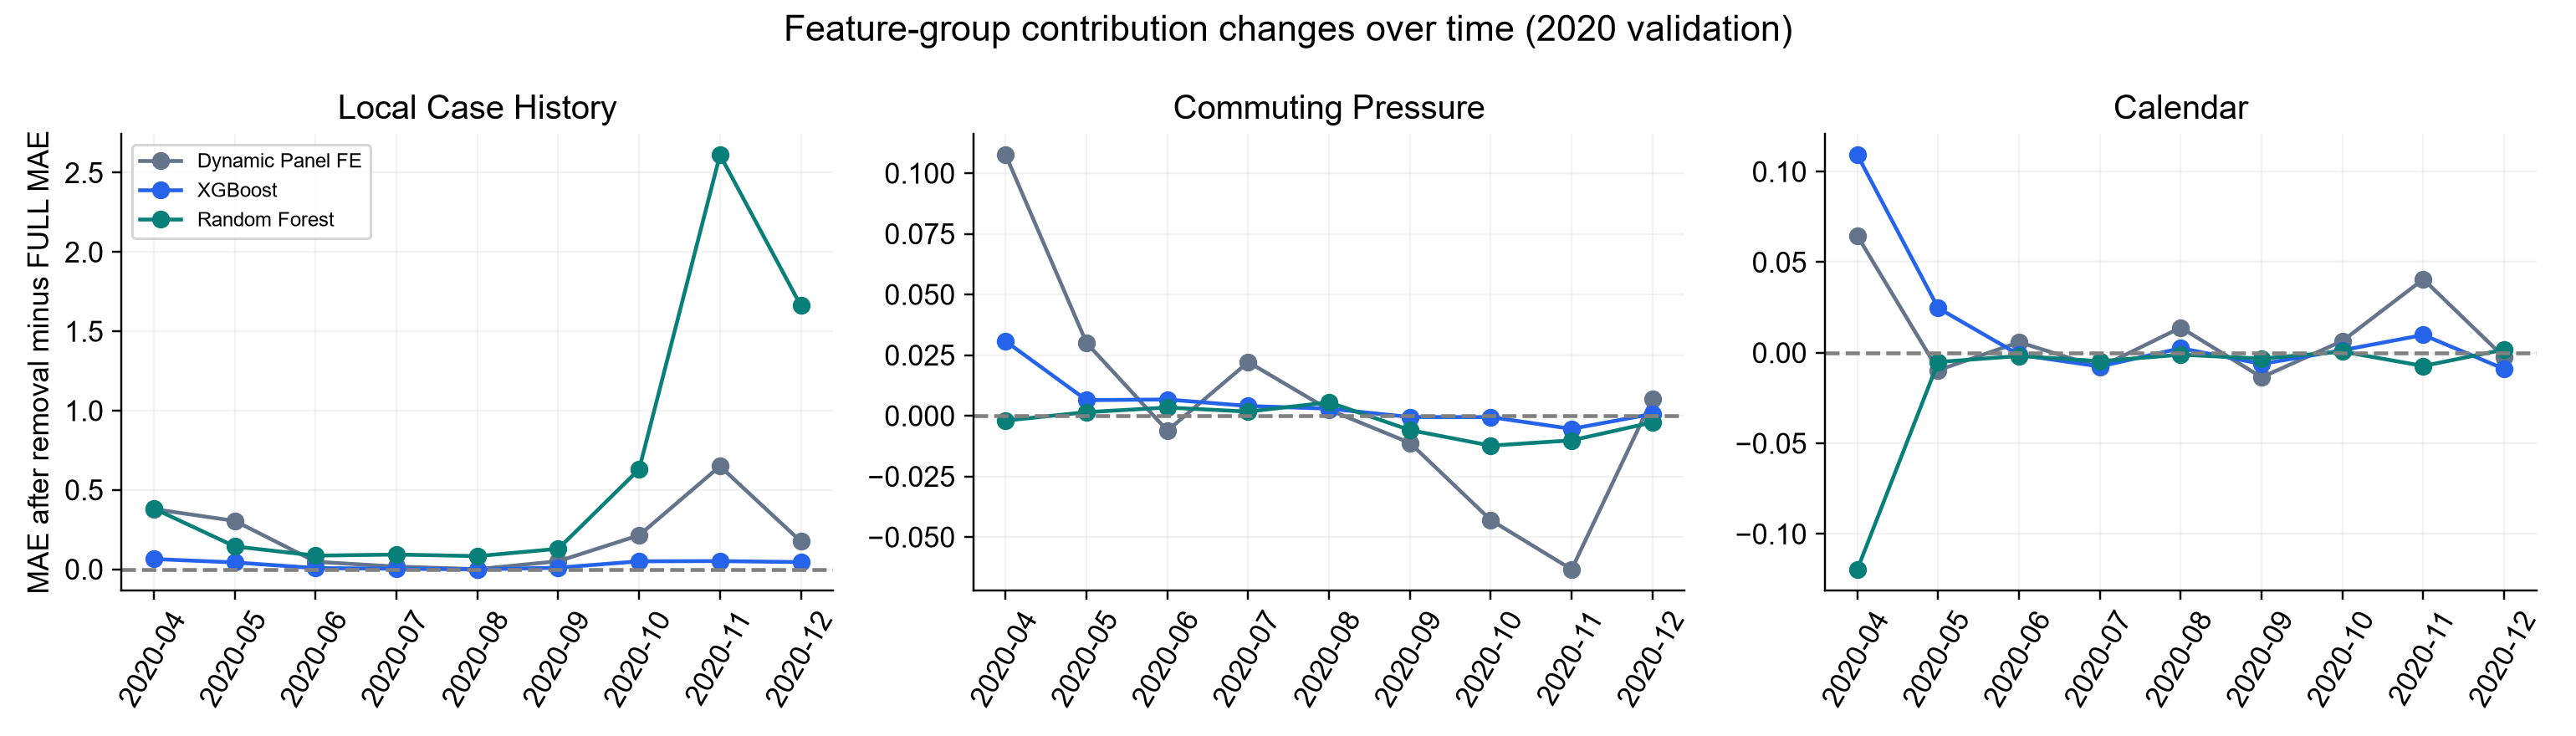

,model,drop_group,variant,direction_agreement,decline_recall,flat_recall,rise_recall,balanced_direction_accuracy,shape_agreement,change_MAE,acceleration_MAE
0,Dynamic Panel FE,local_case_history,FULL,0.281552,0.474345,0.091843,0.585552,0.383913,0.126116,0.896647,1.589743
1,Dynamic Panel FE,local_case_history,DROP,0.369421,0.484554,0.255173,0.553442,0.431056,0.217840,0.877350,1.558658
2,Dynamic Panel FE,commuting_pressure,FULL,0.281552,0.474345,0.091843,0.585552,0.383913,0.126116,0.896647,1.589743
3,Dynamic Panel FE,commuting_pressure,DROP,0.269607,0.537021,0.067832,0.532399,0.379084,0.117210,0.899458,1.597532
4,Dynamic Panel FE,calendar,FULL,0.281552,0.474345,0.091843,0.585552,0.383913,0.126116,0.896647,1.589743
5,Dynamic Panel FE,calendar,DROP,0.274151,0.369280,0.102807,0.625425,0.365838,0.121916,0.870573,1.539748
6,XGBoost,local_case_history,FULL,0.227357,0.475964,0.003779,0.564862,0.348201,0.089951,0.870869,1.548966
7,XGBoost,local_case_history,DROP,0.263058,0.504807,0.065627,0.539520,0.369985,0.125623,0.872585,1.552664
8,XGBoost,commuting_pressure,FULL,0.227357,0.475964,0.003779,0.564862,0.348201,0.089951,0.870869,1.548966
9,XGBoost,commuting_pressure,DROP,0.227146,0.486470,0.002230,0.557708,0.348803,0.089163,0.870259,1.547546


In [5]:
display(pd.read_csv(OUTPUT/"group_ablation_by_horizon.csv"))
display(Image(filename=str(OUTPUT/"figures"/"04_group_contribution_by_month.png")))
# Supplementary trajectory diagnostics; no extra significance tests.
display(pd.read_csv(OUTPUT/"group_ablation_trajectory_diagnostics.csv"))


## 4. Tree training importance
Rankings are normalized within each weekly fit and then averaged. Unused features get zero. ZIP one-hot importances are summed for RF. XGBoost uses split gain; RF uses impurity reduction, so their numerical values cannot be compared directly. Correlated features can share importance. These charts describe training usage, not independently verified predictive contribution.

XGBoost


,model,feature,feature_group,mean,median,std,nonzero_share,rank
46,XGBoost,cases_mean_7d,rolling_level,0.343297,0.299325,0.206065,1.000000,1.0
45,XGBoost,cases_mean_14d,rolling_level,0.141218,0.064895,0.133509,1.000000,2.0
47,XGBoost,cases_today,core_history,0.084205,0.044743,0.092090,1.000000,3.0
52,XGBoost,region_id,ZIP identity,0.071524,0.034886,0.064639,1.000000,4.0
42,XGBoost,cases_lag_1,core_history,0.051972,0.034765,0.055631,1.000000,5.0
48,XGBoost,days_since_last_observed_case_censored,sparse_history,0.032158,0.013001,0.044918,0.542857,6.0
49,XGBoost,nj_covid_pressure_14d,pressure,0.023083,0.020722,0.017084,1.000000,7.0
50,XGBoost,nj_covid_pressure_7d,pressure,0.021931,0.018271,0.015891,1.000000,8.0
39,XGBoost,case_rate_today_per_100k,local_rates,0.019063,0.013917,0.016015,1.000000,9.0
41,XGBoost,case_std_7d,volatility,0.018096,0.009616,0.016435,1.000000,10.0


Random Forest


,model,feature,feature_group,mean,median,std,nonzero_share,rank
11,Random Forest,cases_mean_7d,rolling_level,0.592223,0.572638,0.241817,1.0,1.0
10,Random Forest,cases_mean_14d,rolling_level,0.213620,0.189314,0.160907,1.0,2.0
12,Random Forest,cases_today,core_history,0.039269,0.008694,0.077084,1.0,3.0
2,Random Forest,case_rate_14d_per_100k,local_rates,0.023530,0.011932,0.021462,1.0,4.0
15,Random Forest,nj_covid_pressure_7d,pressure,0.021513,0.011764,0.018941,1.0,5.0
7,Random Forest,cases_lag_1,core_history,0.016372,0.006161,0.033306,1.0,6.0
5,Random Forest,case_std_14d,volatility,0.015429,0.012388,0.012506,1.0,7.0
14,Random Forest,nj_covid_pressure_14d,pressure,0.015183,0.008719,0.012424,1.0,8.0
3,Random Forest,case_rate_7d_per_100k,local_rates,0.014165,0.008181,0.012192,1.0,9.0
4,Random Forest,case_rate_today_per_100k,local_rates,0.008221,0.004439,0.006331,1.0,10.0


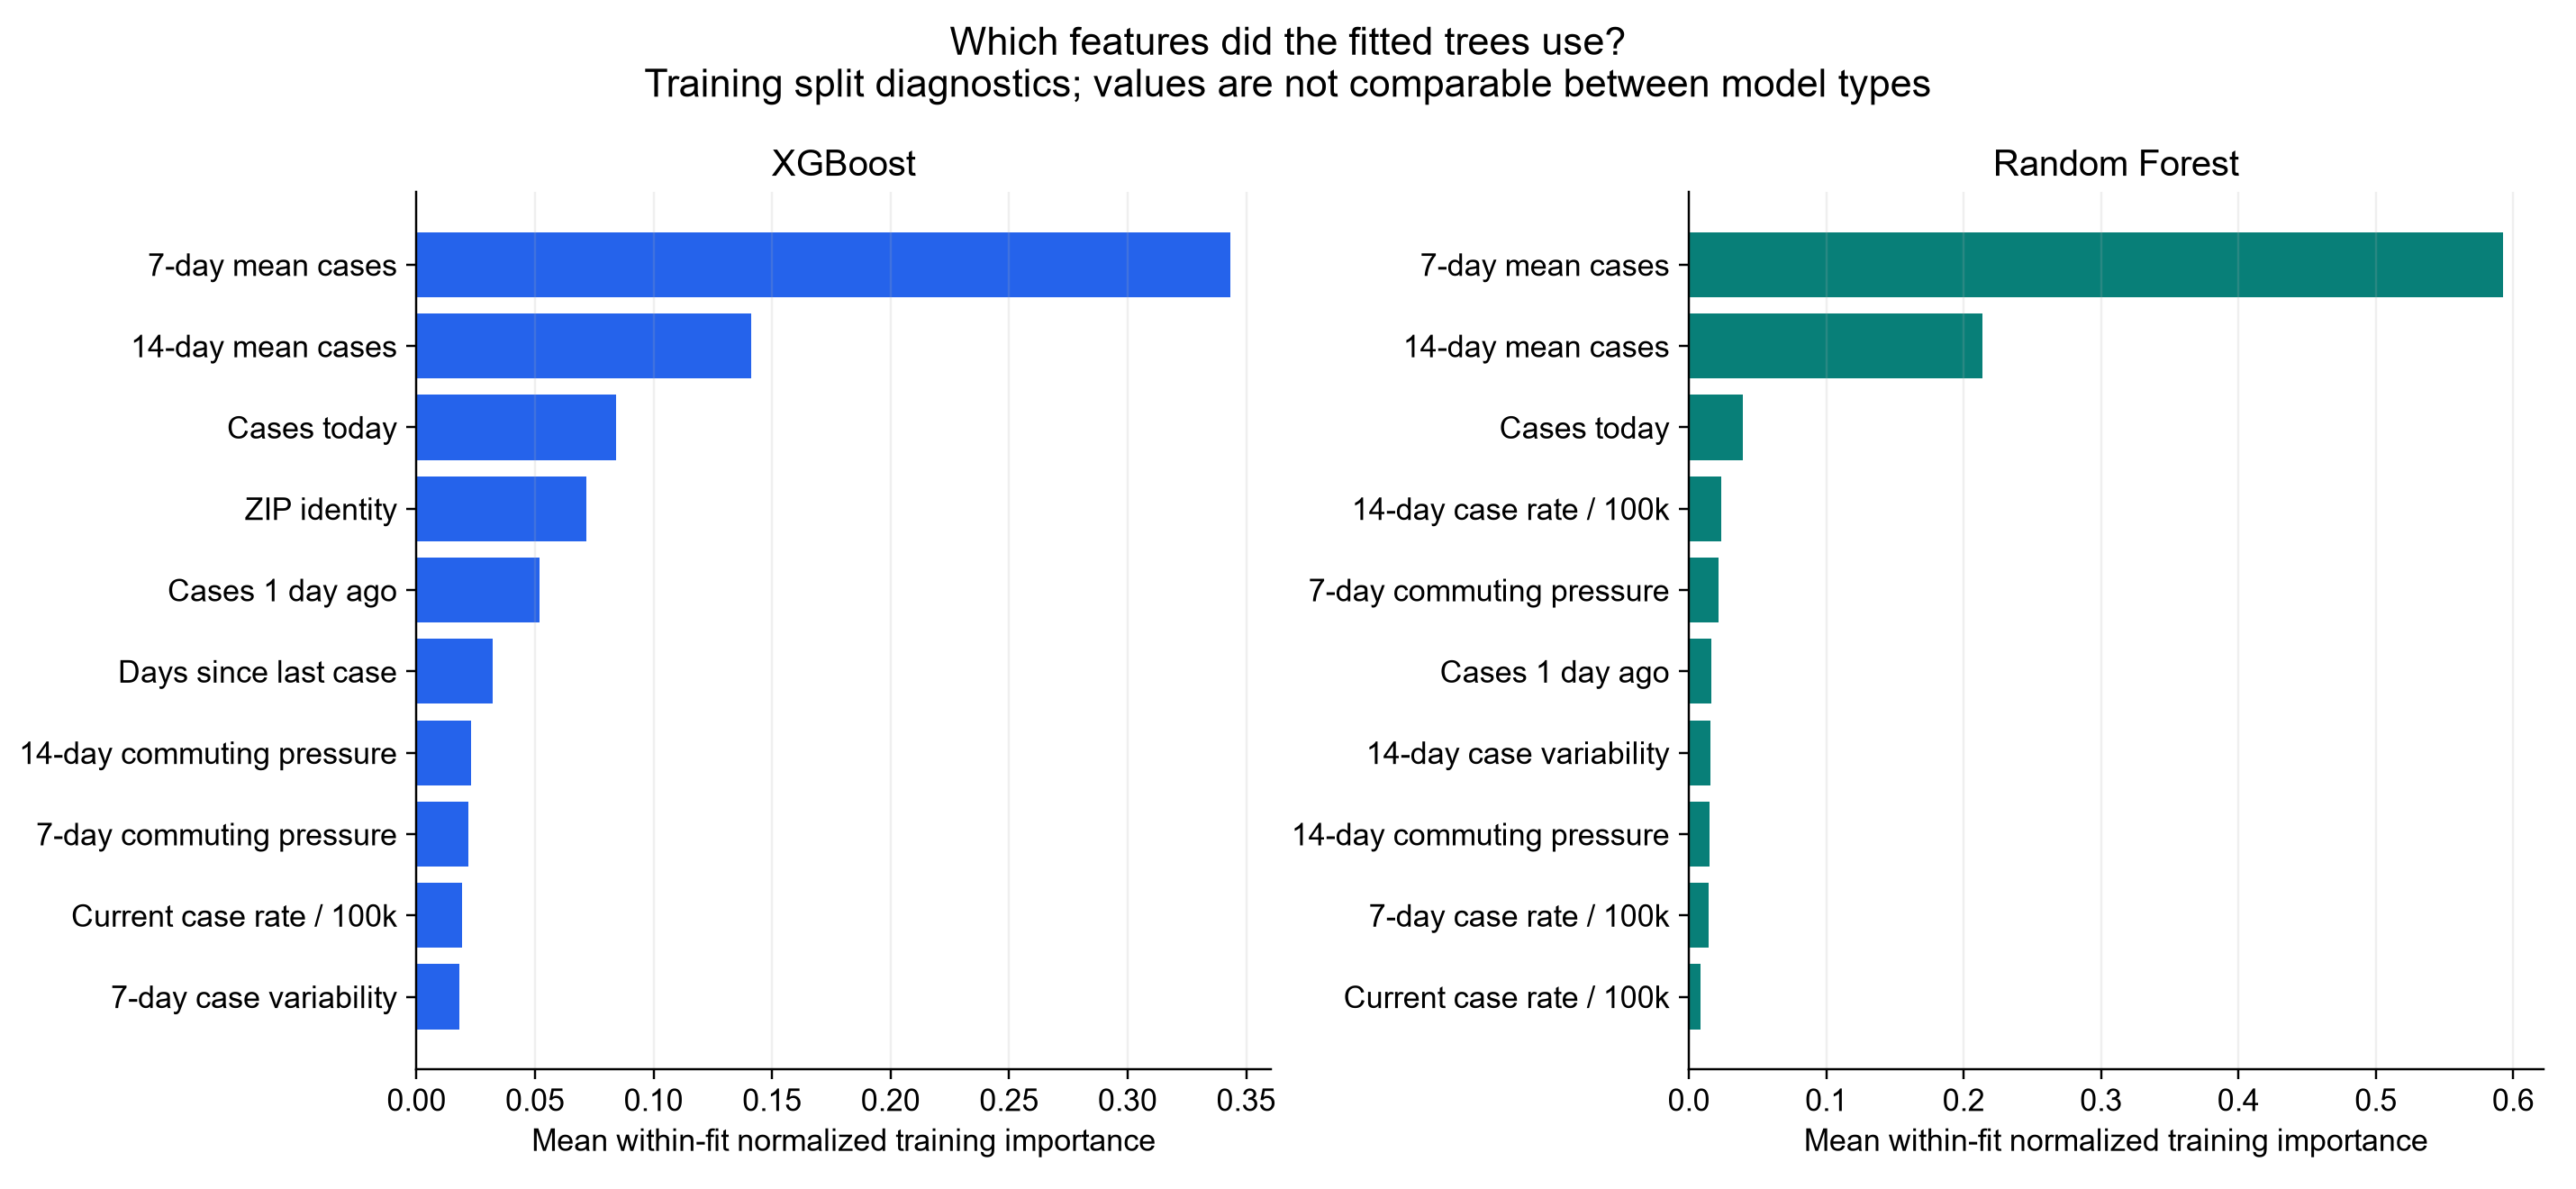

In [6]:
importance=pd.read_csv(OUTPUT/"training_importance_summary.csv")
for model in ["XGBoost","Random Forest"]:
    print(model)
    display(importance[importance.model.eq(model)].sort_values("rank").head(10))
display(Image(filename=str(OUTPUT/"figures"/"01_tree_training_importance.png")))

## 5. Dynamic Panel coefficient stability
Median, 10th/90th percentiles and sign shares across overlapping weekly fits are **descriptive**; these ranges are not confidence intervals. Coefficients depend on feature units, collinearity and specification. A missing coefficient may be unidentifiable or constant in that window; it is not automatically zero. No individual coefficient p-values are asserted, because naive OLS p-values would not address dynamic-FE bias or time/spatial dependence.

,feature,horizon,estimable_fits,total_fits,median_coefficient,p10_coefficient,p90_coefficient,positive_share_of_estimable_fits,negative_share_of_estimable_fits
0,cases_today,1,35,35,0.030372,-0.020959,0.092362,0.771429,0.228571
1,cases_lag_1,1,35,35,0.169655,0.049083,0.249935,1.000000,0.000000
2,cases_lag_7,1,35,35,0.007068,-0.011581,0.059285,0.714286,0.285714
3,cases_lag_14,1,35,35,-0.014560,-0.059359,0.009943,0.228571,0.771429
4,cases_mean_7d,1,35,35,0.412304,0.160250,0.879479,1.000000,0.000000
...,...,...,...,...,...,...,...,...,...
97,target_weekday_3,3,35,35,-0.071366,-0.312639,-0.017185,0.057143,0.942857
98,target_weekday_4,3,35,35,-0.145021,-0.715844,-0.082721,0.000000,1.000000
99,target_weekday_5,3,35,35,-0.147308,-0.531454,-0.078440,0.000000,1.000000
100,target_weekday_6,3,35,35,-0.201148,-0.814175,-0.082626,0.000000,1.000000


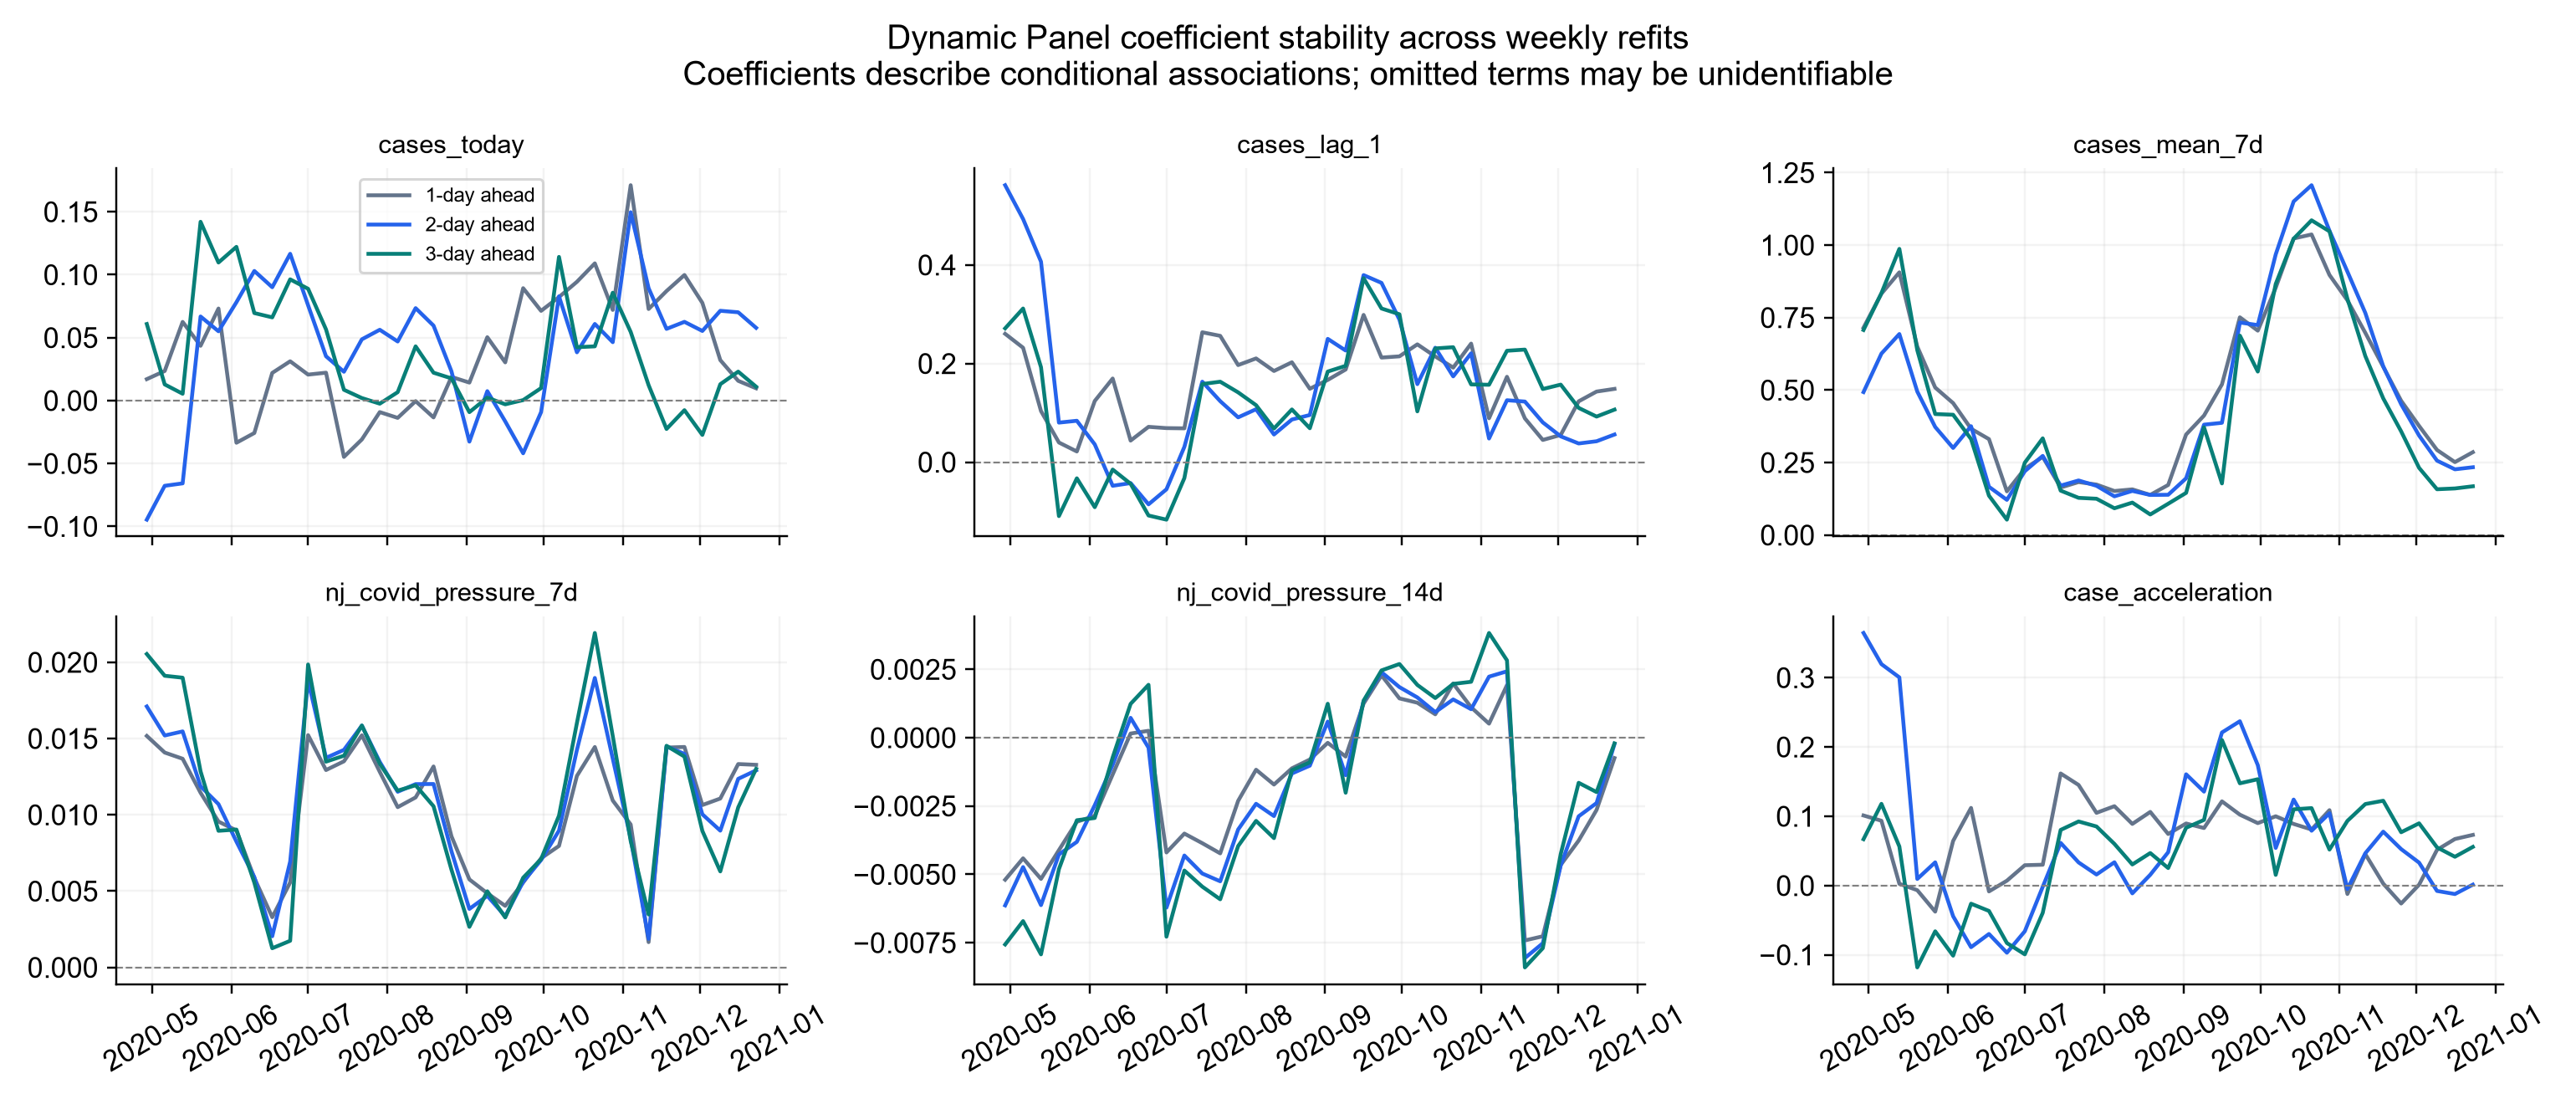

# NJ feature diagnostics: 2020 validation

Main full-feature models remain unchanged. Positive delta means removing the group increases error, so keeping it helps. All comparisons share 585 ZIPs, 243 daily forecast dates, three horizons, 60-day windows and weekly refits.

           model         drop_group  FULL_MAE  DROP_MAE  delta_MAE_DROP_minus_FULL  relative_increase_pct  ci95_low  ci95_high       p_Holm  p_HAC28_Holm_sensitivity
Dynamic Panel FE local_case_history  0.774283  0.956653                   0.182370              23.553383  0.092043   0.288168 4.971981e-05                  0.057218
Dynamic Panel FE commuting_pressure  0.774283  0.767056                  -0.007227              -0.933342 -0.027461   0.010094 1.000000e+00                  1.000000
Dynamic Panel FE           calendar  0.774283  0.778660                   0.004377               0.565338 -0.004488   0.015547 1.000000e+00                  1.000000
         XGBoost local_case_history  0.754299  0.780394        

In [7]:
display(pd.read_csv(OUTPUT/"dp_coefficient_stability.csv"))
display(Image(filename=str(OUTPUT/"figures"/"02_dp_coefficient_stability.png")))
print((OUTPUT/"RESULTS.md").read_text(encoding="utf-8"))

## 6. Related predictors
Raw and within-ZIP correlations are descriptive checks for overlapping information. They do not determine which feature must be removed. Calendar indicators are excluded from this numeric correlation display.

,basis,feature_a,feature_b,correlation
0,raw,cases_today,cases_mean_7d,0.903913
1,raw,cases_lag_1,cases_mean_7d,0.907952
2,raw,cases_mean_7d,cases_mean_14d,0.982606
3,raw,case_std_7d,case_std_14d,0.922866
4,raw,case_acceleration,case_jerk,0.913920
5,raw,nj_covid_pressure_7d,nj_covid_pressure_14d,0.991679
6,within_zip,cases_mean_7d,cases_mean_14d,0.974813
7,within_zip,case_acceleration,case_jerk,0.913922
8,within_zip,nj_covid_pressure_7d,nj_covid_pressure_14d,0.991508


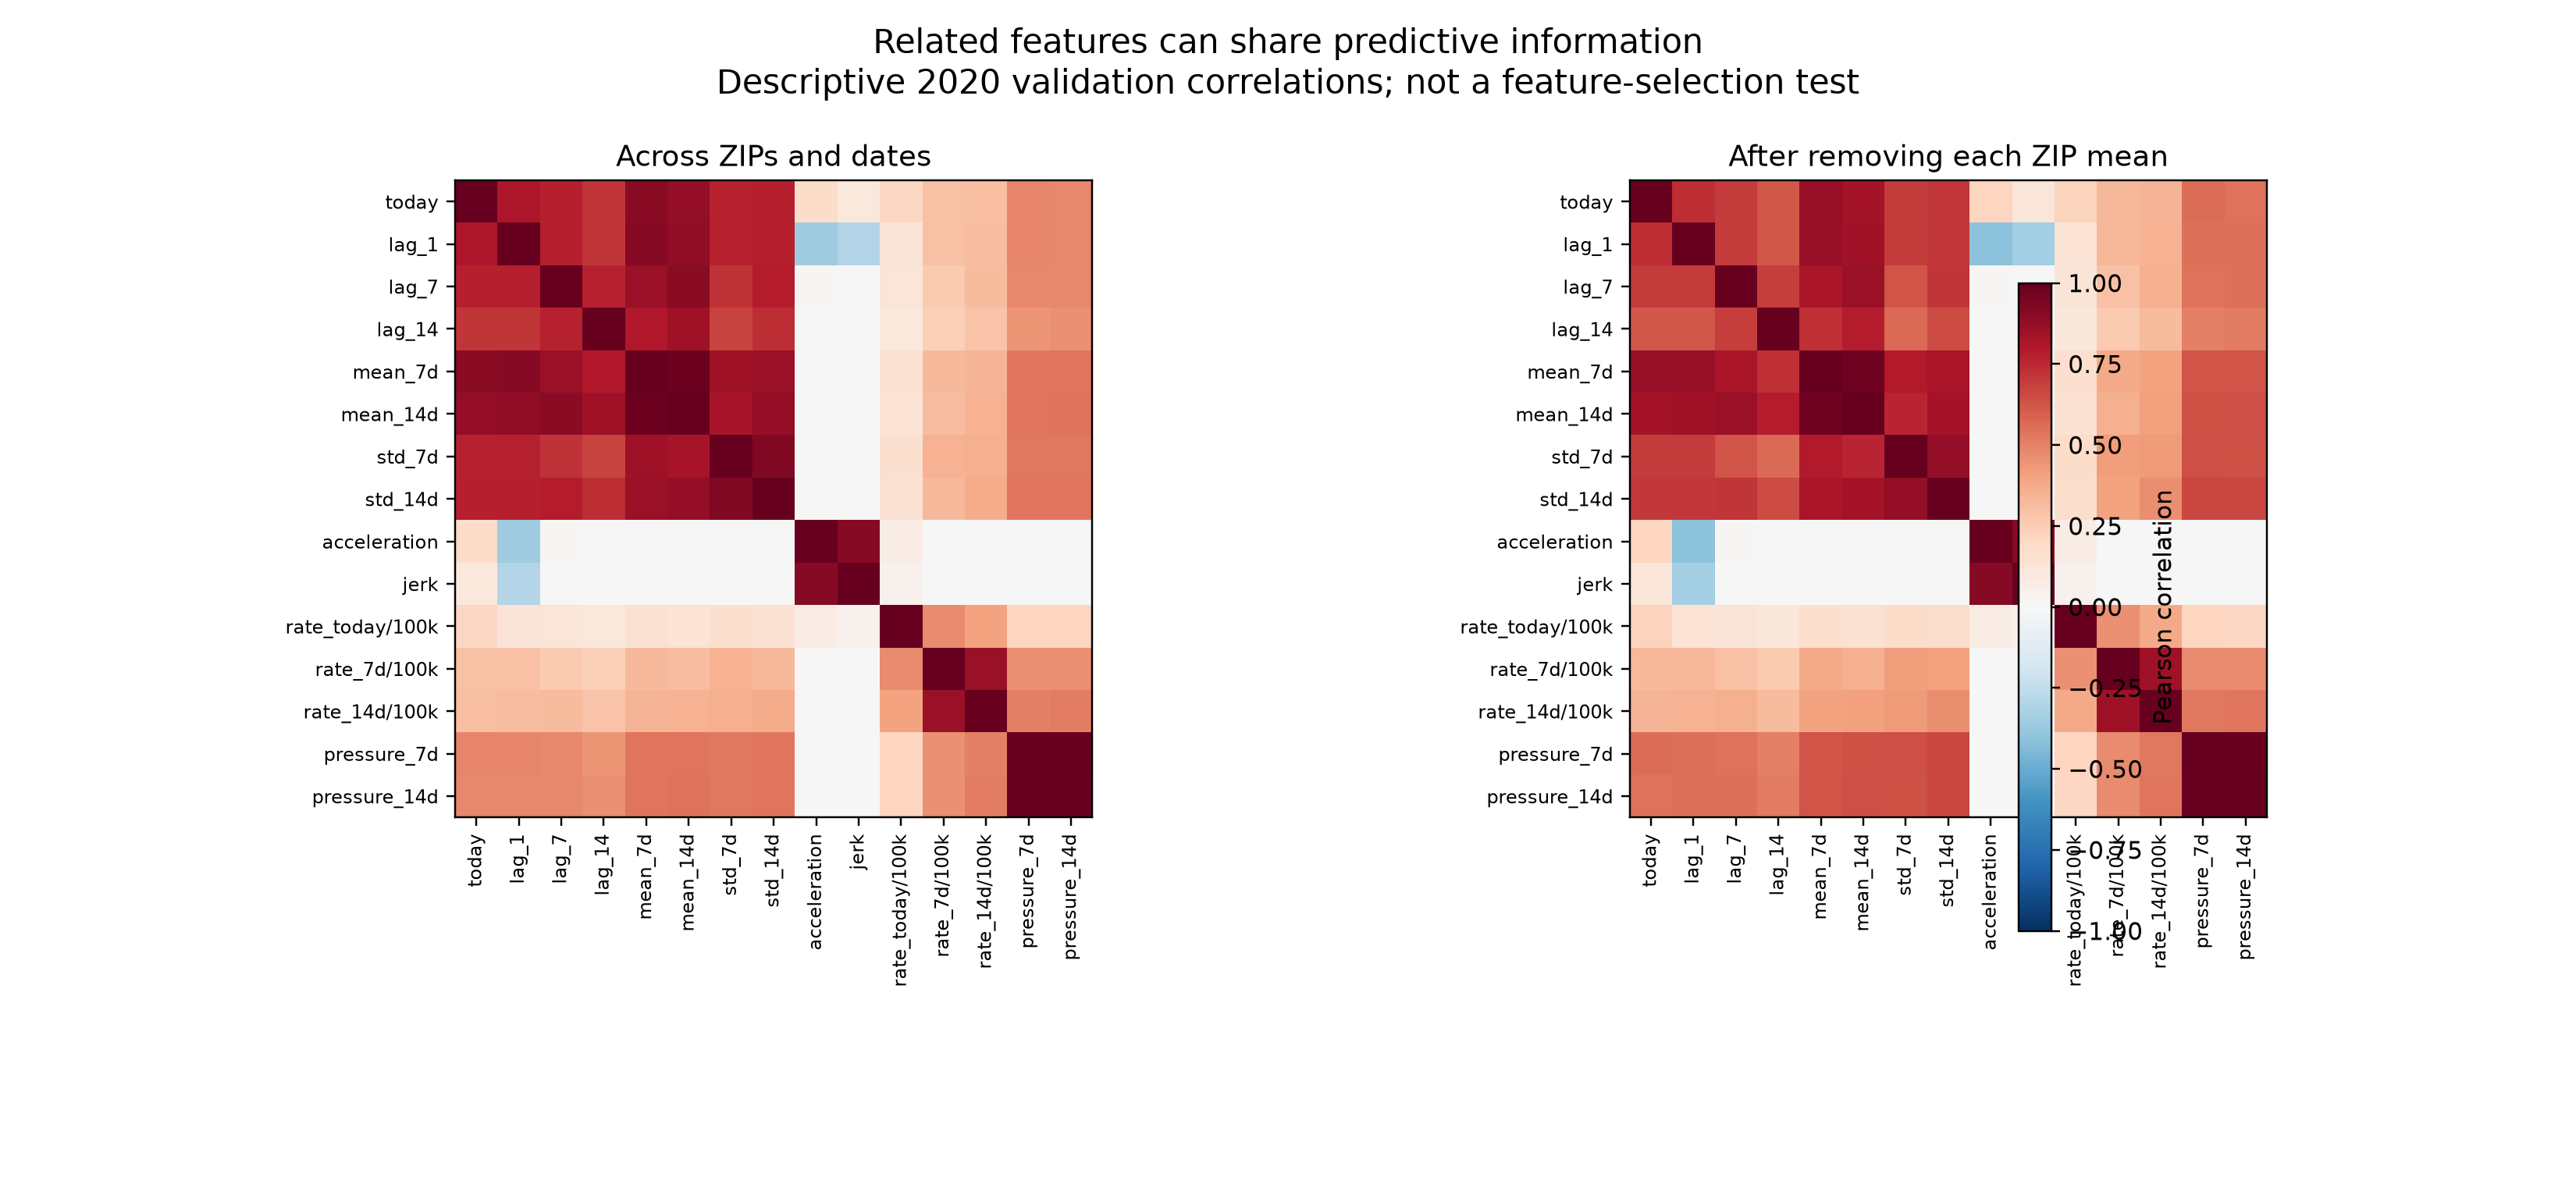

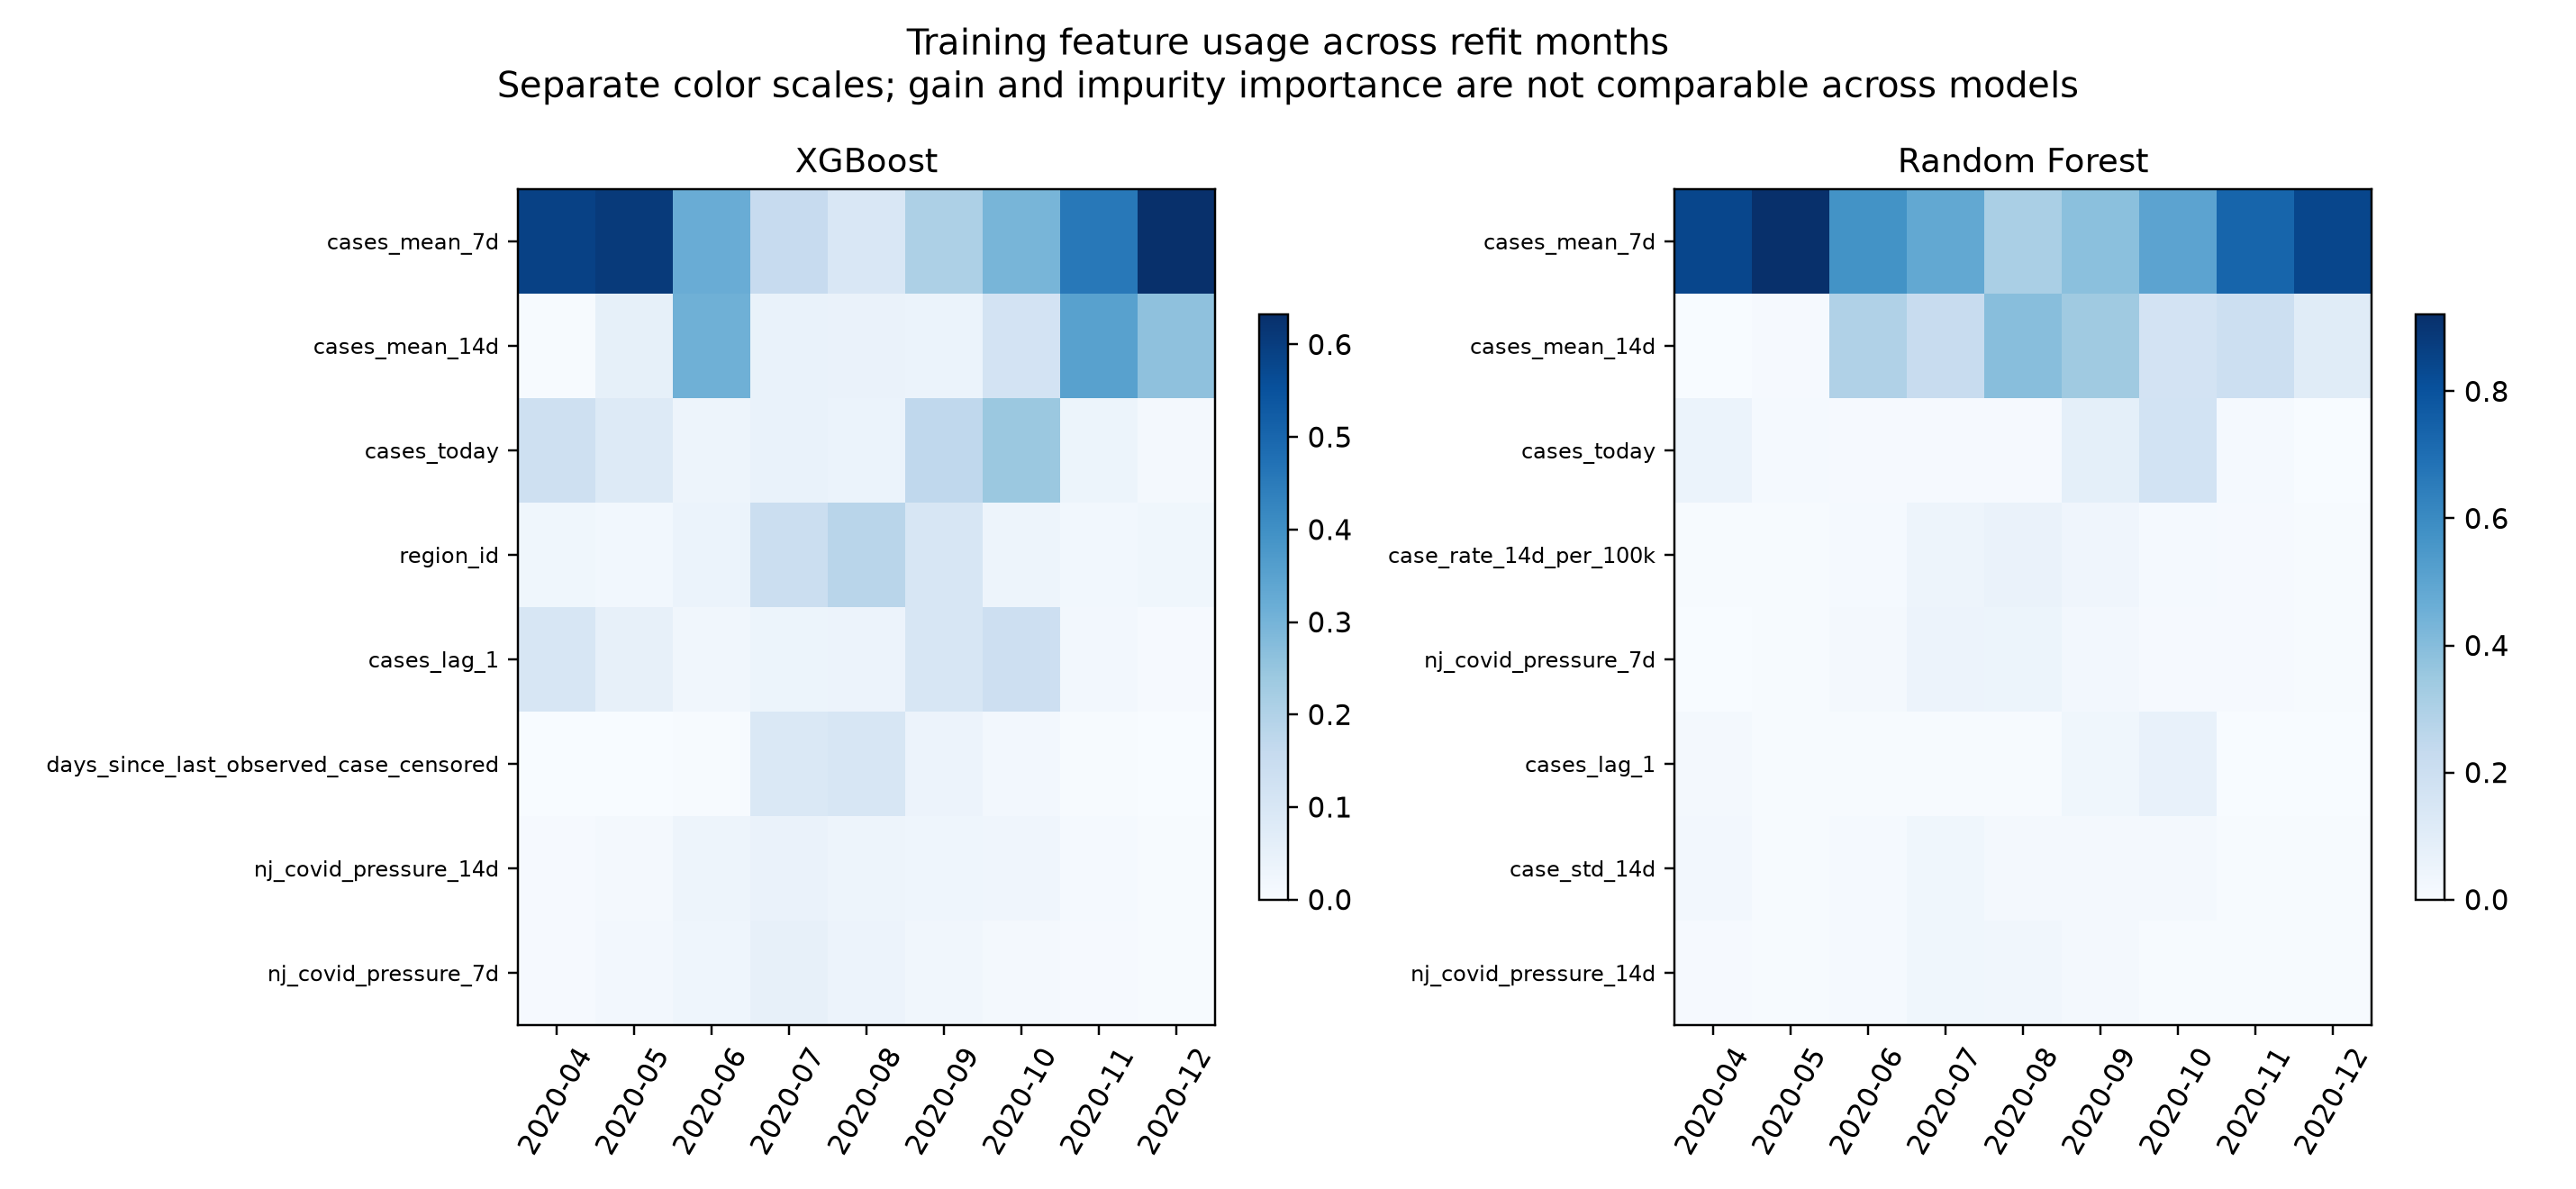

In [8]:
display(pd.read_csv(OUTPUT/"high_correlation_pairs.csv"))
display(Image(filename=str(OUTPUT/"figures"/"05_feature_correlations.png")))
display(Image(filename=str(OUTPUT/"figures"/"06_training_importance_by_month.png")))

## Decision rule for interpretation
Report effect size before p-value. Read the confidence interval and both HAC lag choices. Statistical evidence is exploratory, and small changes may have little practical value. Pressure remains in all main full-feature models. This notebook does not change the outbreak definition, warning threshold, trajectories, or final testing period.